# Unified Notebook: Model Evaluation + Model Improvement

This notebook merges the full content of **Notebook 5** and **Notebook 6** into one executable report with all outputs in a single place.


## Part A - Notebook 5 (Model Evaluation)


# Behavioral Bias Detection — Model Evaluation Report
## Notebook 05: Rigorous Model Evaluation (No Cherry-Picking)

**Goal metric: MACRO F1 — not overall accuracy.**  
Overall accuracy is misleading when class distribution is skewed (rational ≈ 47%).  
Every evaluation cell here uses the **held-out test set only**.

| Section | Focus |
|---------|-------|
| 1 | Dataset & class distribution |
| 2 | Train/test split verification |
| 3 | Model training summary |
| 4 | Core evaluation metrics (test set) |
| 5 | Per-class deep dive |
| 6 | Overfitting analysis (learning curves) |
| 7 | Stratified K-Fold cross-validation |
| 8 | Herd class special analysis |
| 9 | Calibration check |
| 10 | Summary card |


In [1]:
import sys, os
sys.path.insert(0, os.path.join(os.getcwd(), '..', 'src'))

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, accuracy_score, precision_recall_curve, average_precision_score
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, learning_curve
from sklearn.calibration import calibration_curve

from bias_detector import load_data, load_model, BIAS_LABELS, EXCLUDE

plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})

BIAS_COLORS = {
    'disposition'  : '#9b59b6',
    'herd'         : '#e67e22',
    'loss_aversion': '#e74c3c',
    'rational'     : '#27ae60',
}
CLASS_NAMES = ['disposition', 'herd', 'loss_aversion', 'rational']

# ── Load model and data ──────────────────────────────────────────────
model, feature_cols = load_model()
X_train, X_test, y_train, y_test = load_data()

# Also load original split labels (before SMOTE) for comparison sections
merged_df = pd.read_csv('../data/processed/merged_features.csv')
train_idx = np.load('../data/processed/train_indices.npy')
test_idx  = np.load('../data/processed/test_indices.npy')
y_train_original = merged_df.loc[train_idx, 'bias_label'].astype(int).to_numpy()
y_test_original  = merged_df.loc[test_idx, 'bias_label'].astype(int).to_numpy()

# Build ORIGINAL full feature matrix (no SMOTE) for CV/learning curves
full_df = merged_df.copy()
bool_cols = full_df.select_dtypes(include='bool').columns.tolist()
full_df[bool_cols] = full_df[bool_cols].astype(int)

num_cols = full_df.select_dtypes(include=['number']).columns.tolist()
for c in num_cols:
    if full_df[c].isna().any():
        med = full_df[c].median()
        if pd.isna(med):
            med = 0.0
        full_df[c] = full_df[c].fillna(med)

obj_cols = [c for c in full_df.select_dtypes(exclude=['number', 'bool']).columns if c not in EXCLUDE]
for c in obj_cols:
    if full_df[c].isna().any():
        mode_vals = full_df[c].mode(dropna=True)
        fill_val = mode_vals.iloc[0] if len(mode_vals) else 'unknown'
        full_df[c] = full_df[c].fillna(fill_val)
if obj_cols:
    full_df[obj_cols] = full_df[obj_cols].astype(str)
    full_df = pd.get_dummies(full_df, columns=obj_cols, drop_first=True)

X_all_original = full_df[[c for c in full_df.columns if c not in EXCLUDE]].astype(float)
for col in feature_cols:
    if col not in X_all_original.columns:
        X_all_original[col] = 0
X_all_original = X_all_original[feature_cols]
y_all_original = full_df['bias_label'].astype(int).to_numpy()

# Align split matrices to model feature list
for col in feature_cols:
    if col not in X_train.columns:
        X_train[col] = 0
    if col not in X_test.columns:
        X_test[col] = 0
X_train = X_train[feature_cols]
X_test  = X_test[feature_cols]

y_pred       = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)
y_pred_train = model.predict(X_train)

print('✅ Setup complete')
print(f'   Model features       : {len(feature_cols)}')
print(f'   Train size (orig)    : {len(y_train_original):,}')
print(f'   Train size (SMOTE)   : {X_train.shape[0]:,}')
print(f'   Test  size (orig)    : {X_test.shape[0]:,}')
print(f'   CV pool size (orig)  : {X_all_original.shape[0]:,} (no SMOTE)')

✅ Train (before SMOTE): (4562, 44), Test: (1077, 44)
   Classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]  |  Train balance: {3: 2369, 0: 1540, 1: 330, 2: 323}
✅ Setup complete
   Model features       : 44
   Train size (orig)    : 4,562
   Train size (SMOTE)   : 4,562
   Test  size (orig)    : 1,077
   CV pool size (orig)  : 5,639 (no SMOTE)


---
## Section 1 — Dataset & Class Distribution

Raw dataset shape: (5639, 14)

  Raw Dataset — Class Distribution
  ────────────────────────────────────────
  rational          2916  (51.7%)
  disposition       1923  (34.1%)
  herd               400  (7.1%)
  loss_aversion      400  (7.1%)
  ────────────────────────────────────────
  TOTAL             5639


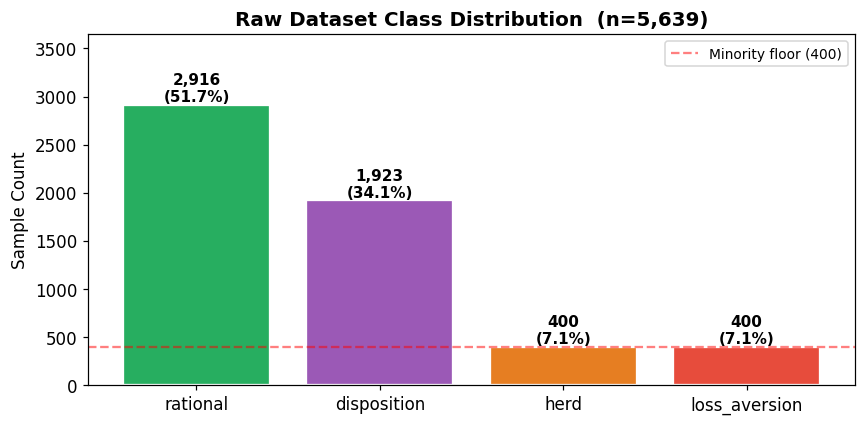

In [2]:
# ── Load raw decisions CSV ───────────────────────────────────────────
raw_df = pd.read_csv('../synthetic_decisions.csv')
print(f'Raw dataset shape: {raw_df.shape}')

# Class distribution table
vc = raw_df['bias_type'].value_counts()
dist_df = pd.DataFrame({
    'Class'     : vc.index,
    'Count'     : vc.values,
    'Percentage': (vc.values / vc.values.sum() * 100).round(2),
})
print('\n  Raw Dataset — Class Distribution')
print('  ' + '─'*40)
for _, row in dist_df.iterrows():
    print(f"  {row['Class']:<16} {int(row['Count']):>5}  ({row['Percentage']:.1f}%)")
print('  ' + '─'*40)
print(f"  {'TOTAL':<16} {vc.values.sum():>5}")

# Bar chart
fig, ax = plt.subplots(figsize=(8, 4))
colors  = [BIAS_COLORS.get(c, '#7f8c8d') for c in vc.index]
bars    = ax.bar(vc.index, vc.values, color=colors, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, vc.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
            f'{val:,}\n({val/vc.sum()*100:.1f}%)',
            ha='center', fontsize=10, fontweight='bold')
ax.set_title(f'Raw Dataset Class Distribution  (n={vc.sum():,})', fontsize=13, fontweight='bold')
ax.set_ylabel('Sample Count')
ax.set_ylim(0, vc.max() * 1.25)
ax.axhline(vc.min(), color='red', linestyle='--', alpha=0.5, label=f'Minority floor ({vc.min()})')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()


  Class Distribution Comparison
  ───────────────────────────────────────────────────────
  Label             ID  Train (orig)   Train+SMOTE
  ───────────────────────────────────────────────────────
  disposition        0         1,540         1,540
  herd               1           330           330
  loss_aversion      2           323           323
  rational           3         2,369         2,369


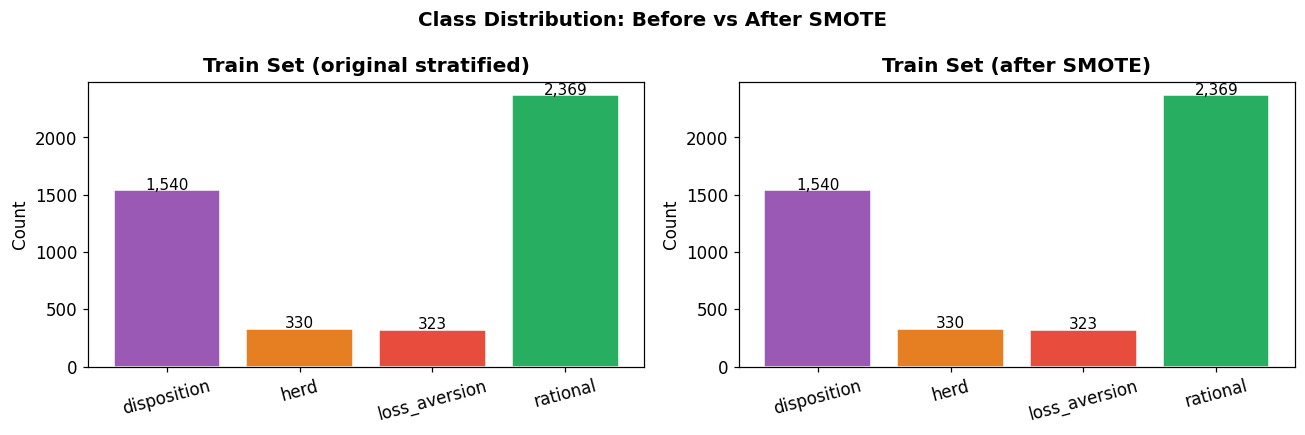

In [3]:
# ── Before vs After SMOTE class counts ──────────────────────────────
# "Before" = original train split (pre-SMOTE)
# "After"  = train data after SMOTE

before_counts = dict(zip(*np.unique(y_train_original, return_counts=True)))
after_counts  = dict(zip(*np.unique(y_train, return_counts=True)))

print('\n  Class Distribution Comparison')
print('  ' + '─'*55)
print(f"  {'Label':<16} {'ID':>3}  {'Train (orig)':>12}  {'Train+SMOTE':>12}")
print('  ' + '─'*55)
for cls_id, cls_name in sorted(BIAS_LABELS.items()):
    b = before_counts.get(cls_id, 0)
    a = after_counts.get(cls_id, 0)
    print(f"  {cls_name:<16} {cls_id:>3}  {b:>12,}  {a:>12,}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, counts, title in zip(
    axes,
    [before_counts, after_counts],
    ['Train Set (original stratified)', 'Train Set (after SMOTE)']
):
    names  = [BIAS_LABELS[k] for k in sorted(counts)]
    vals   = [counts[k] for k in sorted(counts)]
    colors = [BIAS_COLORS.get(n, '#7f8c8d') for n in names]
    bars   = ax.bar(names, vals, color=colors, edgecolor='white')
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                f'{val:,}', ha='center', fontsize=10)
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=15)
plt.suptitle('Class Distribution: Before vs After SMOTE', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## Section 2 — Train vs Test Split Verification

In [4]:
train_idx = np.load('../data/processed/train_indices.npy')
test_idx  = np.load('../data/processed/test_indices.npy')

# Verify no overlap
overlap = set(train_idx) & set(test_idx)
print(f'  Total samples     : {len(train_idx) + len(test_idx):,}')
print(f'  Train size        : {len(train_idx):,}')
print(f'  Test  size        : {len(test_idx):,}')
print(f'  Test  percentage  : {len(test_idx)/(len(train_idx)+len(test_idx))*100:.1f}%')
print(f'  Index overlap     : {len(overlap)}  '
      f'{"✅ NO LEAKAGE" if len(overlap)==0 else "❌ DATA LEAKAGE DETECTED"}')

# Class distribution in each split (from saved data, before SMOTE)
merged = pd.read_csv('../data/processed/merged_features.csv')
if 'bias_label' in merged.columns:
    train_labels = merged['bias_label'].iloc[train_idx]
    test_labels  = merged['bias_label'].iloc[test_idx]

    print('\n  Class distribution in splits (before SMOTE):')
    print(f"  {'Class':<16} {'Train N':>8}  {'Train %':>8}  {'Test N':>7}  {'Test %':>7}")
    print('  ' + '─'*55)
    for cls_id, cls_name in sorted(BIAS_LABELS.items()):
        tn = (train_labels == cls_id).sum()
        tt = (test_labels  == cls_id).sum()
        print(f"  {cls_name:<16} {tn:>8,}  {tn/len(train_labels)*100:>7.1f}%  "
              f"{tt:>7,}  {tt/len(test_labels)*100:>6.1f}%")
    print('  (Near-equal percentages confirm stratified split worked correctly ✅)')

  Total samples     : 5,639
  Train size        : 4,562
  Test  size        : 1,077
  Test  percentage  : 19.1%
  Index overlap     : 0  ✅ NO LEAKAGE

  Class distribution in splits (before SMOTE):
  Class             Train N   Train %   Test N   Test %
  ───────────────────────────────────────────────────────
  disposition         1,540     33.8%      383    35.6%
  herd                  330      7.2%       70     6.5%
  loss_aversion         323      7.1%       77     7.1%
  rational            2,369     51.9%      547    50.8%
  (Near-equal percentages confirm stratified split worked correctly ✅)


---
## Section 3 — Model Training Summary

In [5]:
print('  XGBoost Hyperparameters:')
print('  ' + '─'*45)
for k, v in model.get_params().items():
    if v is not None and v != 'deprecated':
        print(f'    {k:<25}: {v}')

best_it = getattr(model, 'best_iteration', None)
print(f'\n  Number of trees (n_estimators)   : {model.n_estimators}')
print(f'  Best iteration (early stopping)  : {best_it if best_it else "N/A"}')
print(f'  Number of features used          : {len(feature_cols)}')

  XGBoost Hyperparameters:
  ─────────────────────────────────────────────
    objective                : multi:softprob
    colsample_bytree         : 0.8
    early_stopping_rounds    : 20
    enable_categorical       : False
    eval_metric              : mlogloss
    learning_rate            : 0.05
    max_depth                : 6
    missing                  : nan
    n_estimators             : 300
    n_jobs                   : -1
    random_state             : 42
    subsample                : 0.8
    use_label_encoder        : False
    num_class                : 4

  Number of trees (n_estimators)   : 300
  Best iteration (early stopping)  : 299
  Number of features used          : 44


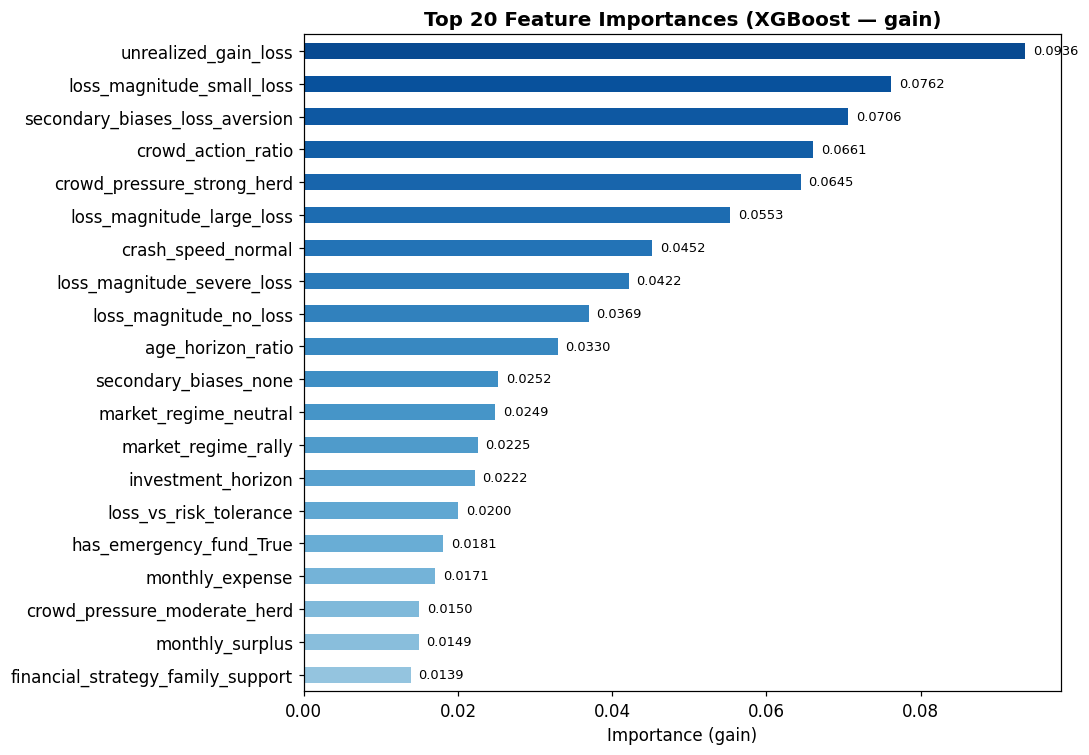

  Top feature: unrealized_gain_loss  (0.0936)


In [6]:
# Feature importance plot — top 20 by gain
feat_imp = pd.Series(model.feature_importances_, index=feature_cols).sort_values(ascending=False)
top20    = feat_imp.head(20)

fig, ax = plt.subplots(figsize=(10, 7))
colors  = plt.cm.Blues(np.linspace(0.4, 0.9, len(top20)))[::-1]
top20.plot(kind='barh', ax=ax, color=colors)
ax.invert_yaxis()
ax.set_title('Top 20 Feature Importances (XGBoost — gain)', fontsize=13, fontweight='bold')
ax.set_xlabel('Importance (gain)')
for i, (feat, val) in enumerate(top20.items()):
    ax.text(val + 0.001, i, f'{val:.4f}', va='center', fontsize=8.5)
plt.tight_layout()
plt.show()
print(f'  Top feature: {top20.index[0]}  ({top20.iloc[0]:.4f})')

---
## Section 4 — Core Evaluation Metrics (TEST SET ONLY)

> ⚠️ **All metrics below are computed on the held-out test set only.**  
> Training data is never used for evaluation.

In [7]:
# 4a. Overall accuracy + overfitting gap
train_acc = accuracy_score(y_train, y_pred_train)
test_acc  = accuracy_score(y_test,  y_pred)
gap       = train_acc - test_acc
macro_f1  = f1_score(y_test, y_pred, average='macro')
weighted_f1 = f1_score(y_test, y_pred, average='weighted')

print(f"  Train Accuracy   : {train_acc:.4f}  ({train_acc*100:.2f}%)")
print(f"  Test  Accuracy   : {test_acc:.4f}  ({test_acc*100:.2f}%)")
flag = '⚠️  POTENTIAL OVERFITTING' if gap > 0.05 else '✅ Acceptable'
print(f"  Overfitting Gap  : {gap:.4f}  ({gap*100:.2f}%)  — {flag}")
print(f"  Macro F1 Score   : {macro_f1:.4f}  ← THIS is the paper metric")
print(f"  Weighted F1      : {weighted_f1:.4f}")

  Train Accuracy   : 0.9259  (92.59%)
  Test  Accuracy   : 0.9276  (92.76%)
  Overfitting Gap  : -0.0017  (-0.17%)  — ✅ Acceptable
  Macro F1 Score   : 0.8311  ← THIS is the paper metric
  Weighted F1      : 0.9154


In [8]:
# 4b. Full classification report — the honest metric
print('  Classification Report — TEST SET ONLY')
print('  ' + '─'*65)
cr_text = classification_report(
    y_test, y_pred,
    target_names=CLASS_NAMES,
    digits=4
)
print(cr_text)

cr_dict = classification_report(
    y_test, y_pred,
    target_names=CLASS_NAMES,
    output_dict=True
)

# Warn for low-performing classes
for cls in CLASS_NAMES:
    if cls not in cr_dict:
        continue
    r  = cr_dict[cls]['recall']
    f1 = cr_dict[cls]['f1-score']
    if r < 0.60:
        print(f"  ⚠️  WARNING: {cls} recall = {r:.4f} < 0.60 — model frequently misses this class")
    if f1 < 0.50:
        print(f"  ❌  WARNING: {cls} F1 = {f1:.4f} < 0.50 — functionally unreliable for this class")

  Classification Report — TEST SET ONLY
  ─────────────────────────────────────────────────────────────────
               precision    recall  f1-score   support

  disposition     0.8634    0.9739    0.9153       383
         herd     1.0000    0.9857    0.9928        70
loss_aversion     1.0000    0.2857    0.4444        77
     rational     0.9657    0.9781    0.9718       547

     accuracy                         0.9276      1077
    macro avg     0.9573    0.8058    0.8311      1077
 weighted avg     0.9340    0.9276    0.9154      1077

  ⚠️  WARNING: loss_aversion recall = 0.2857 < 0.60 — model frequently misses this class
  ❌  WARNING: loss_aversion F1 = 0.4444 < 0.50 — functionally unreliable for this class


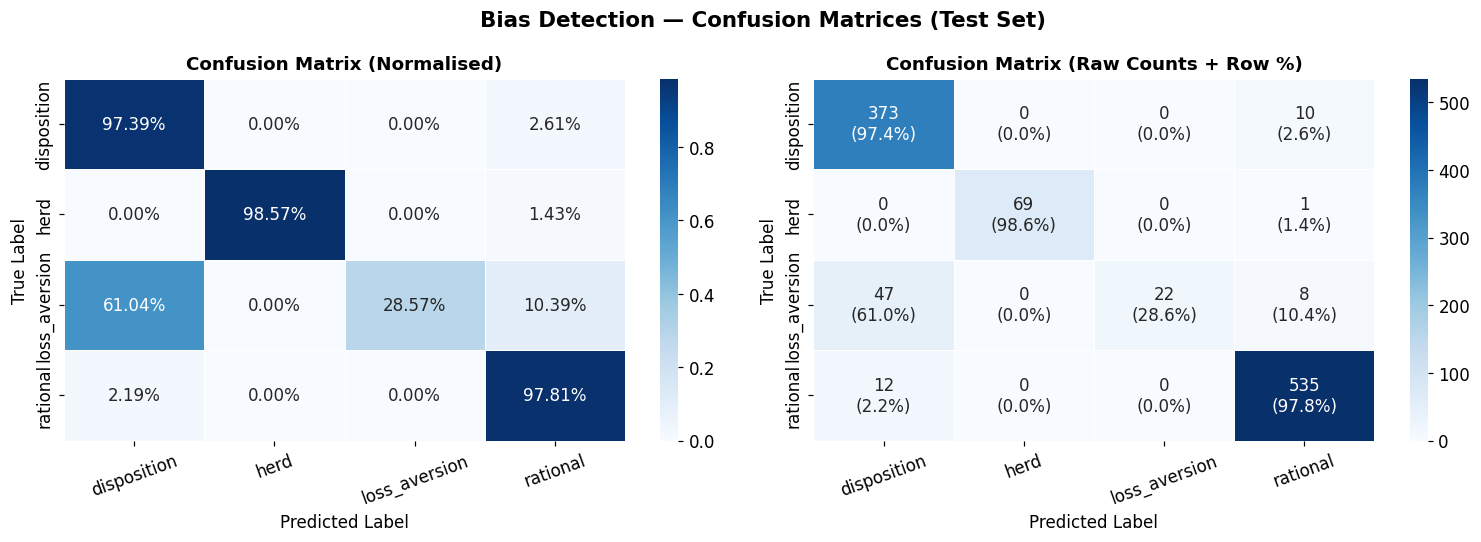

  Macro F1: 0.8311  ← report this in the paper, not accuracy


In [9]:
# 4c. Confusion matrix — normalised + raw
cm_norm = confusion_matrix(y_test, y_pred, normalize='true')
cm_raw  = confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Normalised
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues', ax=axes[0],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.5)
axes[0].set_title('Confusion Matrix (Normalised)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')
axes[0].tick_params(axis='x', rotation=20)

# Raw counts — annotated with count + %
annot_labels = np.array([
    [f'{r}\n({r/cm_raw[i].sum()*100:.1f}%)' for r in row]
    for i, row in enumerate(cm_raw)
])
sns.heatmap(cm_raw, annot=annot_labels, fmt='', cmap='Blues', ax=axes[1],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.5)
axes[1].set_title('Confusion Matrix (Raw Counts + Row %)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')
axes[1].tick_params(axis='x', rotation=20)

plt.suptitle('Bias Detection — Confusion Matrices (Test Set)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../results/figures/confusion_matrix_eval.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'  Macro F1: {macro_f1:.4f}  ← report this in the paper, not accuracy')

---
## Section 5 — Per-Class Deep Dive


  ── DISPOSITION (class 0) ──────────────────────────
     Precision : 0.8634
     Recall    : 0.9739
     F1 Score  : 0.9153
     Support   : 383
     Correct   : 373/383 (97.4%)

  ── HERD (class 1) ──────────────────────────
     Precision : 1.0000
     Recall    : 0.9857
     F1 Score  : 0.9928
     Support   : 70
     Correct   : 69/70 (98.6%)

  ── LOSS_AVERSION (class 2) ──────────────────────────
     Precision : 1.0000
     Recall    : 0.2857  ⚠️ < 0.60
     F1 Score  : 0.4444  ❌ < 0.50
     Support   : 77
     Correct   : 22/77 (28.6%)
     ⚠️  Only 29% of actual loss_aversion cases were caught!

  ── RATIONAL (class 3) ──────────────────────────
     Precision : 0.9657
     Recall    : 0.9781
     F1 Score  : 0.9718
     Support   : 547
     Correct   : 535/547 (97.8%)


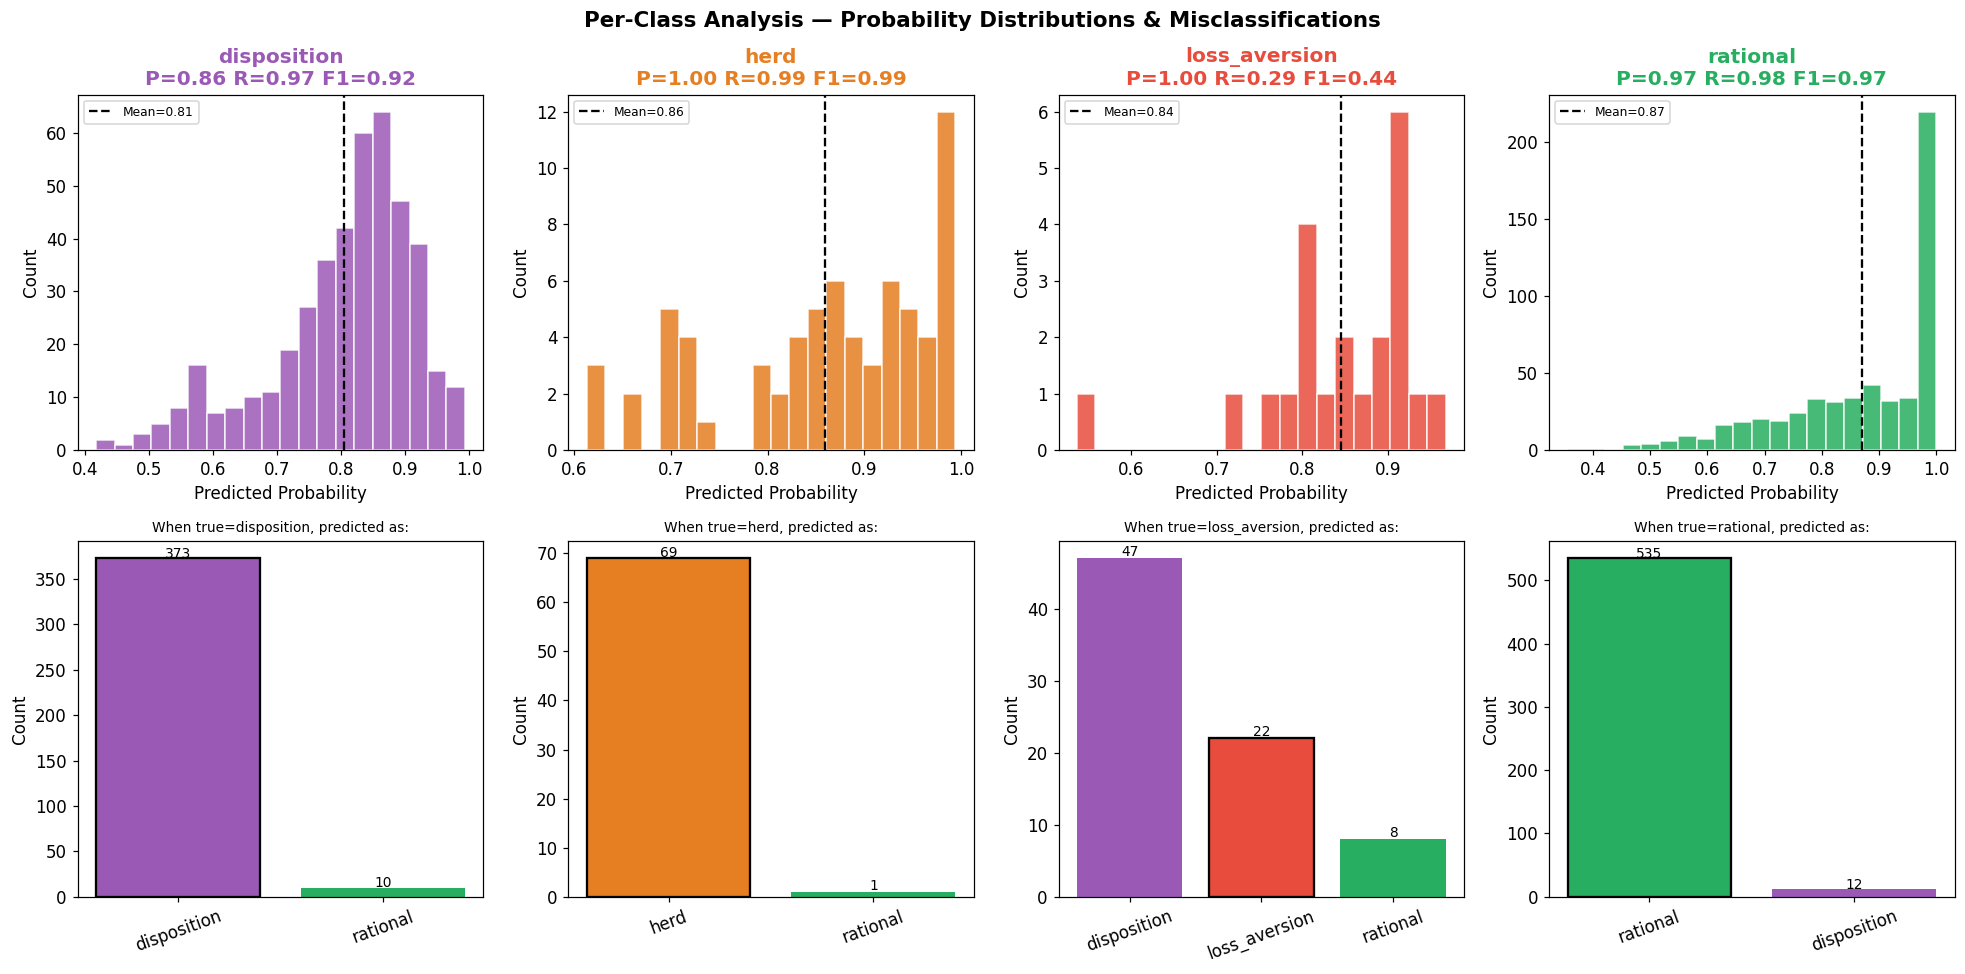

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
fig.suptitle('Per-Class Analysis — Probability Distributions & Misclassifications',
             fontsize=14, fontweight='bold')

for cls_id, cls_name in enumerate(CLASS_NAMES):
    precision = cr_dict[cls_name]['precision']
    recall    = cr_dict[cls_name]['recall']
    f1        = cr_dict[cls_name]['f1-score']
    support   = int(cr_dict[cls_name]['support'])
    color     = BIAS_COLORS.get(cls_name, '#7f8c8d')

    print(f'\n  ── {cls_name.upper()} (class {cls_id}) ──────────────────────────')
    print(f'     Precision : {precision:.4f}')
    print(f'     Recall    : {recall:.4f}' +
          ('  ⚠️ < 0.60' if recall < 0.60 else ''))
    print(f'     F1 Score  : {f1:.4f}' +
          ('  ❌ < 0.50' if f1 < 0.50 else ''))
    print(f'     Support   : {support}')

    # Probability distribution when model predicts this class
    mask = y_pred == cls_id
    probs_this_class = y_pred_proba[mask, cls_id] if mask.any() else np.array([])

    ax_hist = axes[0, cls_id]
    if len(probs_this_class) > 0:
        ax_hist.hist(probs_this_class, bins=20, color=color, edgecolor='white', alpha=0.85)
        ax_hist.axvline(probs_this_class.mean(), color='black', linestyle='--',
                        label=f'Mean={probs_this_class.mean():.2f}')
        ax_hist.legend(fontsize=8)
    else:
        ax_hist.text(0.5, 0.5, 'No predictions', ha='center', va='center',
                     transform=ax_hist.transAxes, color='red', fontsize=11)
    ax_hist.set_title(f'{cls_name}\nP={precision:.2f} R={recall:.2f} F1={f1:.2f}',
                      fontweight='bold', color=color)
    ax_hist.set_xlabel('Predicted Probability')
    ax_hist.set_ylabel('Count')

    # Misclassification breakdown: when true=cls_name, what is predicted?
    true_mask = y_test == cls_id
    if true_mask.any():
        pred_for_true = y_pred[true_mask]
        miss_counts   = pd.Series(pred_for_true).value_counts()
        miss_names    = [BIAS_LABELS.get(i, str(i)) for i in miss_counts.index]
        miss_colors   = [BIAS_COLORS.get(n, '#7f8c8d') for n in miss_names]
        edge_colors   = ['black' if i == cls_id else 'none' for i in miss_counts.index]

        ax_bar = axes[1, cls_id]
        bars   = ax_bar.bar(miss_names, miss_counts.values, color=miss_colors,
                            edgecolor=edge_colors, linewidth=1.5)
        for bar, val in zip(bars, miss_counts.values):
            ax_bar.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                        str(val), ha='center', fontsize=9)
        ax_bar.set_title(f'When true={cls_name}, predicted as:', fontsize=9)
        ax_bar.set_ylabel('Count')
        ax_bar.tick_params(axis='x', rotation=20)
        correct_n  = (pred_for_true == cls_id).sum()
        print(f'     Correct   : {correct_n}/{true_mask.sum()} ({correct_n/true_mask.sum()*100:.1f}%)')
        if recall < 0.60:
            print(f'     ⚠️  Only {correct_n/true_mask.sum()*100:.0f}% of actual {cls_name} cases were caught!')

plt.tight_layout()
plt.savefig('../results/figures/per_class_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 6 — Overfitting Analysis (Learning Curves)

  Computing learning curves (this takes ~1-2 min)…


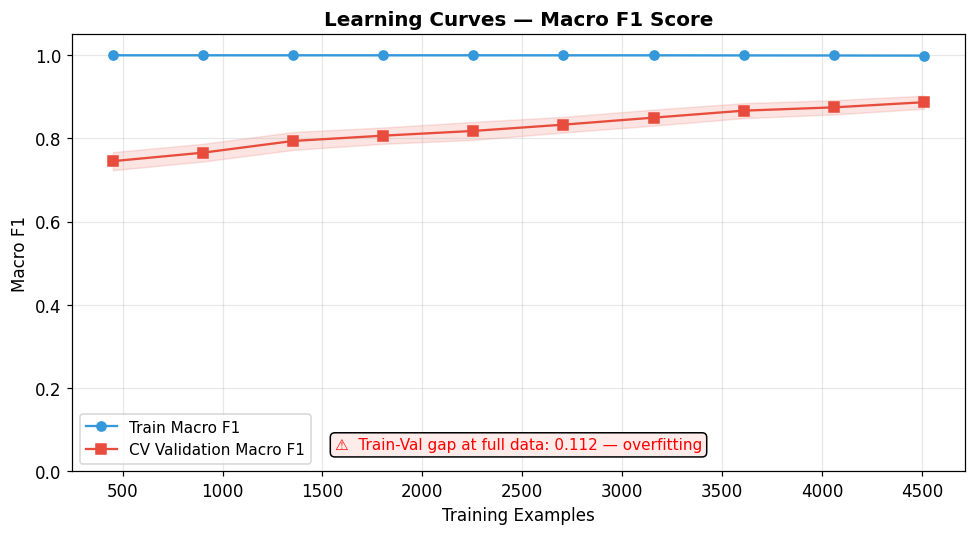

  Train Macro F1 (full data)      : 0.9992
  Val   Macro F1 (full data, CV)  : 0.8871
  Final Train-Val Gap             : 0.1121  (OVERFITTING)


In [11]:
# Use ORIGINAL full dataset (no SMOTE artifacts) for CV-based learning curves
X_all = X_all_original.copy()
y_all = y_all_original.copy()

# CV-safe estimator: remove early stopping requirement (needs eval_set)
cv_params = model.get_params().copy()
cv_params.pop('early_stopping_rounds', None)
cv_model = model.__class__(**cv_params)

print('  Computing learning curves (this takes ~1-2 min)…')
train_sizes, train_scores, val_scores = learning_curve(
    cv_model, X_all, y_all,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
    shuffle=True,
    random_state=42,
)

train_mean = train_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
val_mean   = val_scores.mean(axis=1)
val_std    = val_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(train_sizes, train_mean, 'o-', color='#3498db', label='Train Macro F1')
ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std,
                alpha=0.15, color='#3498db')
ax.plot(train_sizes, val_mean, 's-', color='#e74c3c', label='CV Validation Macro F1')
ax.fill_between(train_sizes, val_mean - val_std, val_mean + val_std,
                alpha=0.15, color='#e74c3c')

ax.set_title('Learning Curves — Macro F1 Score', fontsize=13, fontweight='bold')
ax.set_xlabel('Training Examples')
ax.set_ylabel('Macro F1')
ax.legend(fontsize=10)
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)

gap_at_full = train_mean[-1] - val_mean[-1]
if gap_at_full > 0.10:
    ax.text(0.5, 0.05,
            f'⚠️  Train-Val gap at full data: {gap_at_full:.3f} — overfitting',
            transform=ax.transAxes, ha='center', color='red', fontsize=10,
            bbox=dict(boxstyle='round', facecolor='#fdecea'))

plt.tight_layout()
plt.savefig('../results/figures/learning_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'  Train Macro F1 (full data)      : {train_mean[-1]:.4f}')
print(f'  Val   Macro F1 (full data, CV)  : {val_mean[-1]:.4f}')
ovfit = 'OVERFITTING' if gap_at_full > 0.10 else 'ACCEPTABLE'
print(f'  Final Train-Val Gap             : {gap_at_full:.4f}  ({ovfit})')

---
## Section 7 — Stratified K-Fold Cross-Validation

This is the **definitive generalisation estimate** — more reliable than a single train/test split.

  5-Fold Stratified Cross-Validation (on full dataset):
  ───────────────────────────────────────────────────────


  accuracy       : 0.8847 ± 0.0116
                   folds: ['0.8768', '0.8759', '0.8980', '0.8732', '0.8997']


  f1_macro       : 0.8837 ± 0.0161 ← report in paper
                   folds: ['0.8918', '0.8766', '0.8848', '0.8583', '0.9067']


  f1_weighted    : 0.8842 ± 0.0117
                   folds: ['0.8770', '0.8755', '0.8967', '0.8720', '0.9000']
  ───────────────────────────────────────────────────────


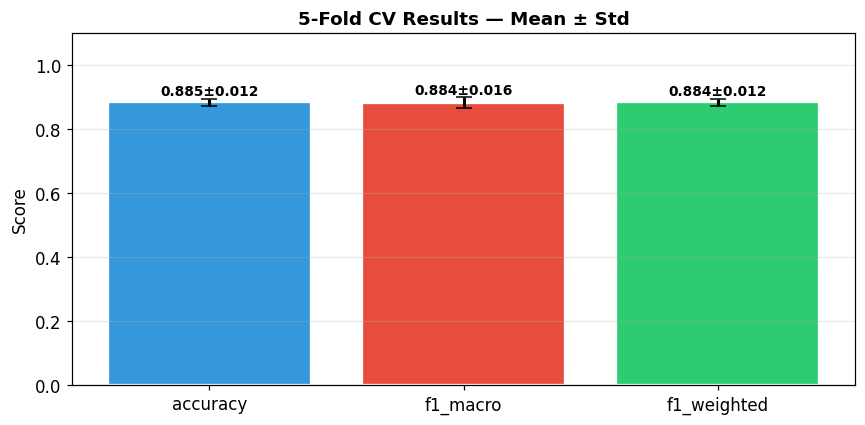

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Reuse CV-safe estimator (no early stopping dependency on eval_set)
cv_params = model.get_params().copy()
cv_params.pop('early_stopping_rounds', None)
cv_model = model.__class__(**cv_params)

print('  5-Fold Stratified Cross-Validation (on full dataset):')
print('  ' + '─'*55)
cv_results = {}
for metric in ['accuracy', 'f1_macro', 'f1_weighted']:
    scores = cross_val_score(
        cv_model, X_all, y_all,
        cv=cv, scoring=metric, n_jobs=-1
    )
    cv_results[metric] = scores
    star = ' ← report in paper' if metric == 'f1_macro' else ''
    print(f'  {metric:<15}: {scores.mean():.4f} ± {scores.std():.4f}{star}')
    print(f'  {"":15}  folds: {[f"{s:.4f}" for s in scores]}')

print('  ' + '─'*55)

# Visualise CV spread
fig, ax = plt.subplots(figsize=(8, 4))
metrics  = list(cv_results.keys())
means    = [cv_results[m].mean() for m in metrics]
stds     = [cv_results[m].std()  for m in metrics]
colors_cv = ['#3498db', '#e74c3c', '#2ecc71']
bars = ax.bar(metrics, means, color=colors_cv, edgecolor='white', linewidth=1.5)
ax.errorbar(metrics, means, yerr=stds, fmt='none', color='black', capsize=5, linewidth=2)
for bar, m, s in zip(bars, means, stds):
    ax.text(bar.get_x() + bar.get_width()/2, m + s + 0.01,
            f'{m:.3f}±{s:.3f}', ha='center', fontsize=9, fontweight='bold')
ax.set_ylim(0, 1.1)
ax.set_title('5-Fold CV Results — Mean ± Std', fontsize=12, fontweight='bold')
ax.set_ylabel('Score')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('../results/figures/cv_results.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 8 — Herd Class Special Analysis

**This class originally had only 14 samples.** After the `fix_herd_imbalance.py` fix it now has ~400 in the raw CSV. Extra scrutiny is warranted.

  Herd class ID                    : 1
  Herd samples in test set         : 70
  Herd precision (on test set)     : 1.0000
  Herd recall    (on test set)     : 0.9857
  Herd F1        (on test set)     : 0.9928
  Predicted as herd (total)        : 69

  Herd test samples → predictions:
  --------------------------------------------------
  ✅ Sample   1: true=herd  pred=herd            conf=0.722
  ✅ Sample   2: true=herd  pred=herd            conf=0.975
  ✅ Sample   3: true=herd  pred=herd            conf=0.913
  ✅ Sample   4: true=herd  pred=herd            conf=0.994
  ✅ Sample   5: true=herd  pred=herd            conf=0.736
  ✅ Sample   6: true=herd  pred=herd            conf=0.704
  ✅ Sample   7: true=herd  pred=herd            conf=0.879
  ✅ Sample   8: true=herd  pred=herd            conf=0.891
  ✅ Sample   9: true=herd  pred=herd            conf=0.923
  ✅ Sample  10: true=herd  pred=herd            conf=0.692
  ✅ Sample  11: true=herd  pred=herd            conf=0.824
  ✅ Sample 

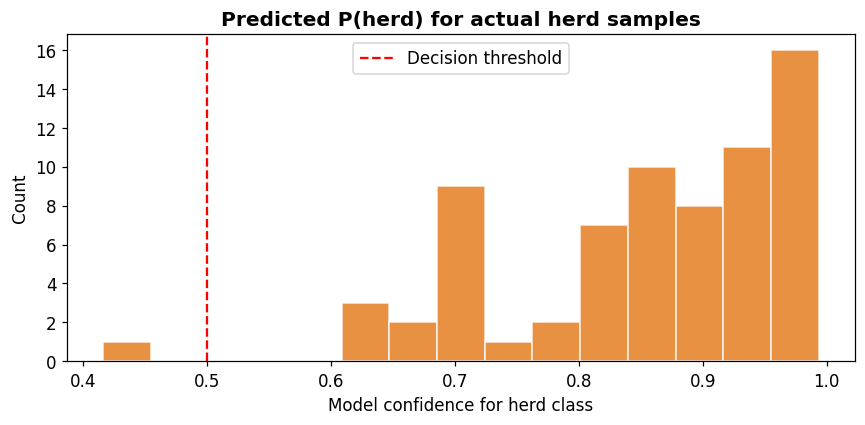

In [13]:
HERD_ID = [k for k, v in BIAS_LABELS.items() if v == 'herd'][0]   # should be 1

# Herd samples in test set
herd_test_mask = y_test == HERD_ID
n_herd_test    = herd_test_mask.sum()

print(f'  Herd class ID                    : {HERD_ID}')
print(f'  Herd samples in test set         : {n_herd_test}')

if n_herd_test == 0:
    print('  ⚠️  No herd samples in test set — cannot evaluate herd recall')
else:
    herd_pred      = y_pred[herd_test_mask]
    herd_proba     = y_pred_proba[herd_test_mask]
    herd_recall    = (herd_pred == HERD_ID).sum() / n_herd_test

    # Precision: how many predicted as herd are actually herd?
    pred_herd_mask = y_pred == HERD_ID
    n_pred_herd    = pred_herd_mask.sum()
    herd_precision = (y_test[pred_herd_mask] == HERD_ID).sum() / max(n_pred_herd, 1)
    herd_f1        = cr_dict.get('herd', {}).get('f1-score', 0.0)

    print(f'  Herd precision (on test set)     : {herd_precision:.4f}')
    print(f'  Herd recall    (on test set)     : {herd_recall:.4f}'
          + ('  ⚠️ < 0.50 — see warning below' if herd_recall < 0.50 else ''))
    print(f'  Herd F1        (on test set)     : {herd_f1:.4f}')
    print(f'  Predicted as herd (total)        : {n_pred_herd}')

    if herd_f1 < 0.50:
        print('\n  ❌  WARNING: Herd F1 < 0.50')
        print('     RECOMMENDATION: The herd class remains under-represented even after SMOTE.')
        print('     Possible actions:')
        print('       1. Collect more real herd observations (more data > oversampling)')
        print('       2. Use cost-sensitive learning (class_weight for herd)')
        print('       3. Report herd F1 as a known limitation in the research paper')

    # Show what each herd test sample was predicted as
    print(f'\n  Herd test samples → predictions:')
    print(f'  {"-"*50}')
    correct_count = 0
    for i, (pred, probs) in enumerate(zip(herd_pred, herd_proba)):
        pred_name = BIAS_LABELS.get(pred, str(pred))
        marker    = '✅' if pred == HERD_ID else '❌'
        conf      = probs[pred]
        if pred == HERD_ID:
            correct_count += 1
        if i < 20:   # show first 20 to keep output manageable
            print(f'  {marker} Sample {i+1:>3}: true=herd  pred={pred_name:<15} conf={conf:.3f}')
    if n_herd_test > 20:
        print(f'  ... ({n_herd_test - 20} more)')
    print(f'  {"-"*50}')
    print(f'  Correct: {correct_count}/{n_herd_test}')

    # Visualise herd prob distributions
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(herd_proba[:, HERD_ID], bins=15, color='#e67e22', edgecolor='white', alpha=0.85)
    ax.axvline(0.5, color='red', linestyle='--', label='Decision threshold')
    ax.set_title('Predicted P(herd) for actual herd samples', fontweight='bold')
    ax.set_xlabel('Model confidence for herd class')
    ax.set_ylabel('Count')
    ax.legend()
    plt.tight_layout()
    plt.show()

---
## Section 9 — Calibration Check

A well-calibrated model: when it says 70% confident, it is right ~70% of the time.  
**This matters** because confidence scores are shown to users in the dashboard.

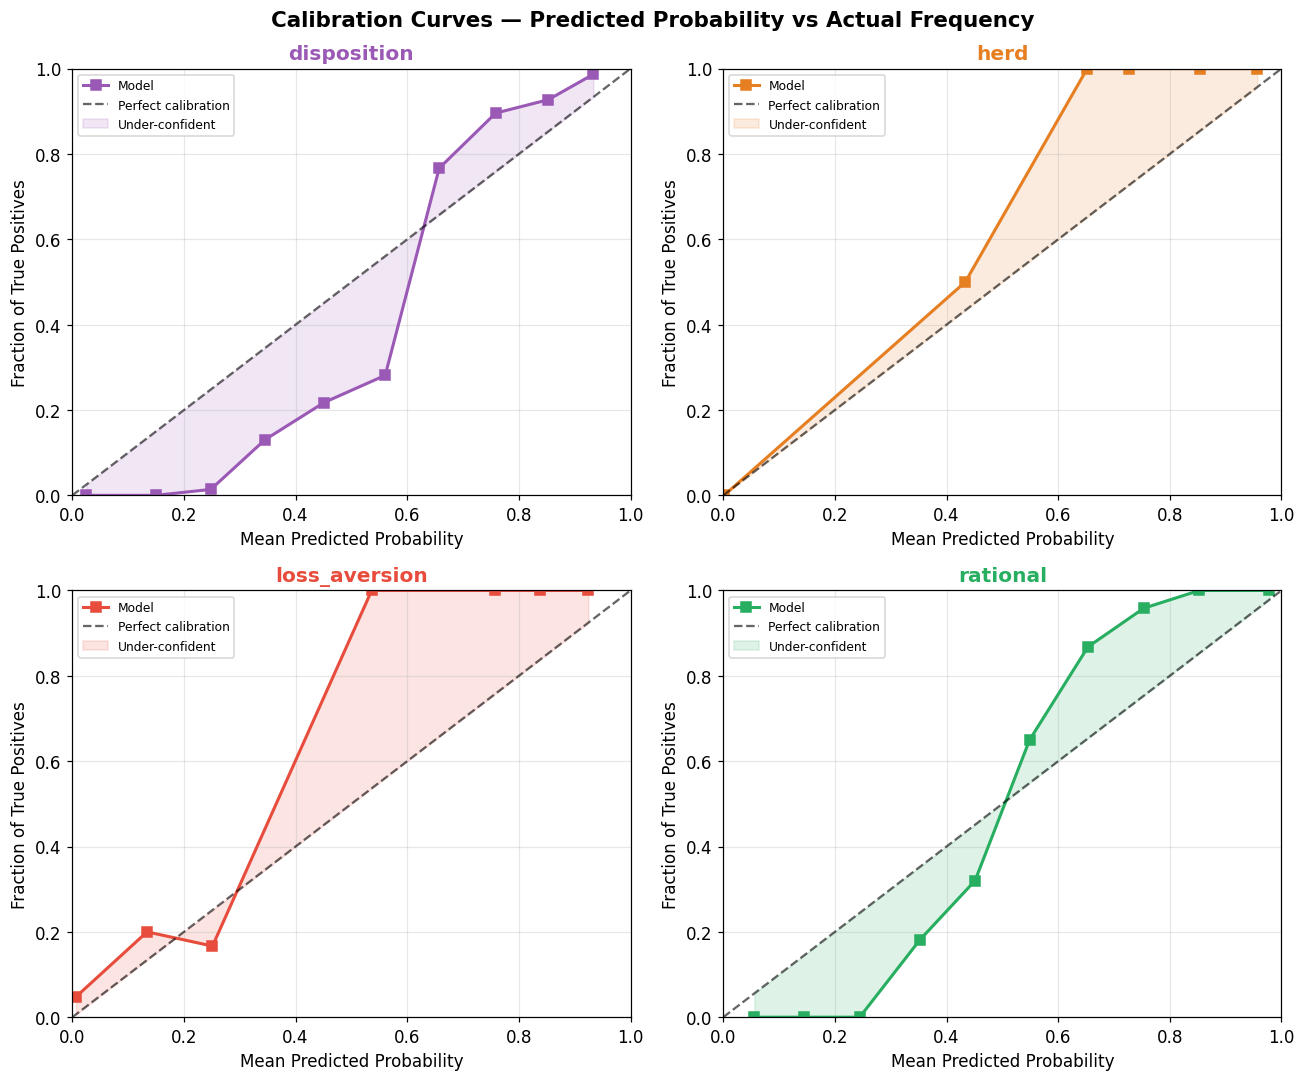

  Interpretation guide:
  • Points on diagonal    → well calibrated
  • Points above diagonal → under-confident (model predicts lower probs than reality)
  • Points below diagonal → over-confident (model is too sure)


In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Calibration Curves — Predicted Probability vs Actual Frequency',
             fontsize=14, fontweight='bold')

for cls_id, (cls_name, ax) in enumerate(zip(CLASS_NAMES, axes.flat)):
    y_bin       = (y_test == cls_id).astype(int)
    prob_pos    = y_pred_proba[:, cls_id]

    if y_bin.sum() < 5:
        ax.text(0.5, 0.5, f'Too few samples\n(n={y_bin.sum()})',
                ha='center', va='center', transform=ax.transAxes)
        ax.set_title(cls_name)
        continue

    try:
        fraction_of_positives, mean_predicted_value = calibration_curve(
            y_bin, prob_pos, n_bins=10
        )
        color = BIAS_COLORS.get(cls_name, '#7f8c8d')
        ax.plot(mean_predicted_value, fraction_of_positives,
                's-', label='Model', color=color, linewidth=2, markersize=6)
        ax.plot([0, 1], [0, 1], 'k--', alpha=0.6, label='Perfect calibration')
        ax.fill_between(mean_predicted_value,
                        fraction_of_positives, mean_predicted_value,
                        alpha=0.15, color=color,
                        label='Over-confident' if fraction_of_positives[-1] < mean_predicted_value[-1]
                        else 'Under-confident')
        ax.set_title(f'{cls_name}', fontweight='bold', color=color)
        ax.set_xlabel('Mean Predicted Probability')
        ax.set_ylabel('Fraction of True Positives')
        ax.legend(fontsize=8)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.grid(alpha=0.3)
    except Exception as e:
        ax.text(0.5, 0.5, f'Calibration error:\n{e}',
                ha='center', va='center', transform=ax.transAxes, fontsize=9)

plt.tight_layout()
plt.savefig('../results/figures/calibration_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print('  Interpretation guide:')
print('  • Points on diagonal    → well calibrated')
print('  • Points above diagonal → under-confident (model predicts lower probs than reality)')
print('  • Points below diagonal → over-confident (model is too sure)')

---
## Section 10 — Summary Card

In [15]:
import json

cv_macro_mean = cv_results['f1_macro'].mean()
cv_macro_std  = cv_results['f1_macro'].std()

per_class_f1 = {cls: cr_dict.get(cls, {}).get('f1-score', 0.0) for cls in CLASS_NAMES}

W = 60
print('╔' + '═'*(W-2) + '╗')
print('║' + ' MODEL EVALUATION SUMMARY — TEST SET'.center(W-2) + '║')
print('╠' + '═'*(W-2) + '╣')

def row(label, value, note=''):
    line = f'  {label:<22}: {value}  {note}'
    print('║' + line.ljust(W-2) + '║')

row('Overall Accuracy', f'{test_acc*100:.2f}%')
row('Macro F1 Score',   f'{macro_f1*100:.2f}%', '← report this in paper')
row('Weighted F1 Score',f'{weighted_f1*100:.2f}%')
row('Train Accuracy',   f'{train_acc*100:.2f}%')
gap_note = '(⚠️  > 5%!)' if gap > 0.05 else '(✅ OK)'
row('Overfitting Gap',  f'{gap*100:.2f}%', gap_note)
print('╠' + '═'*(W-2) + '╣')
print('║' + '  Per-Class F1:'.ljust(W-2) + '║')
for cls in CLASS_NAMES:
    f1v  = per_class_f1[cls]
    note = '← watch this number' if cls == 'herd' else ('⚠️  < 0.50' if f1v < 0.50 else '')
    print('║' + f'    {cls:<18}: {f1v*100:.2f}%  {note}'.ljust(W-2) + '║')
print('╠' + '═'*(W-2) + '╣')
row('5-Fold CV Macro F1 ', f'{cv_macro_mean*100:.2f}% ± {cv_macro_std*100:.2f}%')
print('╚' + '═'*(W-2) + '╝')

# Save to JSON
summary = {
    'test_accuracy'        : round(test_acc,    4),
    'train_accuracy'       : round(train_acc,   4),
    'overfitting_gap'      : round(gap,         4),
    'macro_f1'             : round(macro_f1,    4),
    'weighted_f1'          : round(weighted_f1, 4),
    'cv_macro_f1_mean'     : round(cv_macro_mean, 4),
    'cv_macro_f1_std'      : round(cv_macro_std,  4),
    'per_class_f1'         : {k: round(v, 4) for k, v in per_class_f1.items()},
    'classification_report': cr_dict,
    'confusion_matrix_norm': cm_norm.tolist(),
    'confusion_matrix_raw' : cm_raw.tolist(),
}
report_path = '../results/model_evaluation_report.json'
os.makedirs(os.path.dirname(report_path), exist_ok=True)
with open(report_path, 'w') as f:
    json.dump(summary, f, indent=2)
print(f'\n  ✅ Evaluation report saved → {report_path}')

╔══════════════════════════════════════════════════════════╗
║            MODEL EVALUATION SUMMARY — TEST SET           ║
╠══════════════════════════════════════════════════════════╣
║  Overall Accuracy      : 92.76%                          ║
║  Macro F1 Score        : 83.11%  ← report this in paper  ║
║  Weighted F1 Score     : 91.54%                          ║
║  Train Accuracy        : 92.59%                          ║
║  Overfitting Gap       : -0.17%  (✅ OK)                  ║
╠══════════════════════════════════════════════════════════╣
║  Per-Class F1:                                           ║
║    disposition       : 91.53%                            ║
║    herd              : 99.28%  ← watch this number       ║
║    loss_aversion     : 44.44%  ⚠️  < 0.50                ║
║    rational          : 97.18%                            ║
╠══════════════════════════════════════════════════════════╣
║  5-Fold CV Macro F1    : 88.37% ± 1.61%                  ║
╚═══════════════════════

---
## Part B - Notebook 6 (Model Improvement)

The section below is directly merged from Notebook 6.


# Model Improvement Notebook - v1 to v2

This notebook documents the end-to-end improvement journey for the behavioral bias detector.

Targets:
- Reduce overfitting
- Improve loss_aversion performance
- Validate herd generalisation
- Save reproducible v2 artifacts

In [16]:
import json
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_score,
    learning_curve,
    train_test_split,
)
from sklearn.calibration import calibration_curve
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_sample_weight
from imblearn.over_sampling import SMOTE

ROOT = Path('..').resolve()
DECISIONS_PATH = ROOT / 'synthetic_decisions.csv'
MERGED_PATH = ROOT / 'data' / 'processed' / 'merged_features.csv'
TRAIN_IDX_PATH = ROOT / 'data' / 'processed' / 'train_indices.npy'
TEST_IDX_PATH = ROOT / 'data' / 'processed' / 'test_indices.npy'
REPORT_V1_PATH = ROOT / 'results' / 'model_evaluation_report.json'
REPORT_V2_PATH = ROOT / 'results' / 'model_evaluation_report_v2.json'
REPORT_V2_EXPERIMENT_PATH = ROOT / 'results' / 'model_evaluation_report_v2_experiment.json'
MODEL_V1_PATH = ROOT / 'models' / 'bias_detector_xgboost.pkl'
MODEL_V2_PATH = ROOT / 'models' / 'bias_detector_xgboost_v2.pkl'
MODEL_V2_EXPERIMENT_PATH = ROOT / 'models' / 'bias_detector_xgboost_v2_experiment.pkl'
HERD_REPORT_PATH = ROOT / 'results' / 'herd_generalisation_test.json'

BIAS_LABELS = {0: 'disposition', 1: 'herd', 2: 'loss_aversion', 3: 'rational'}
EXCLUDE = {
    'bias_label', 'decision_label', 'decision', 'bias_type',
    'bias_present', 'user_id', 'decision_id',
    'disposition_strength_profile', 'loss_aversion_profile', 'herd_sensitivity_profile',
}

def preprocess_merged(df: pd.DataFrame):
    df = df.copy()
    bool_cols = df.select_dtypes(include='bool').columns.tolist()
    if bool_cols:
        df[bool_cols] = df[bool_cols].astype(int)

    num_cols = df.select_dtypes(include=['number']).columns.tolist()
    for col in num_cols:
        if df[col].isna().any():
            med = df[col].median()
            df[col] = df[col].fillna(0.0 if pd.isna(med) else med)

    obj_cols = [
        c for c in df.select_dtypes(exclude=['number', 'bool']).columns
        if c not in EXCLUDE
    ]
    if obj_cols:
        df[obj_cols] = df[obj_cols].astype(str)
        df = pd.get_dummies(df, columns=obj_cols, drop_first=True)

    X = df[[c for c in df.columns if c not in EXCLUDE]].astype(float)
    y = df['bias_label'].astype(int)
    return df, X, y

merged_df = pd.read_csv(MERGED_PATH)
train_idx = np.load(TRAIN_IDX_PATH)
test_idx = np.load(TEST_IDX_PATH)

merged_df, X_all, y_all = preprocess_merged(merged_df)
X_train = X_all.loc[train_idx].copy()
X_test = X_all.loc[test_idx].copy()
y_train = y_all.loc[train_idx].to_numpy()
y_test = y_all.loc[test_idx].to_numpy()

print(f'Train shape: {X_train.shape}, Test shape: {X_test.shape}')
print('Train class distribution:', pd.Series(y_train).value_counts().sort_index().to_dict())
print('Test class distribution :', pd.Series(y_test).value_counts().sort_index().to_dict())

Train shape: (4562, 44), Test shape: (1077, 44)
Train class distribution: {0: 1540, 1: 330, 2: 323, 3: 2369}
Test class distribution : {0: 383, 1: 70, 2: 77, 3: 547}


## Section 1 - Before vs After: Data Fix

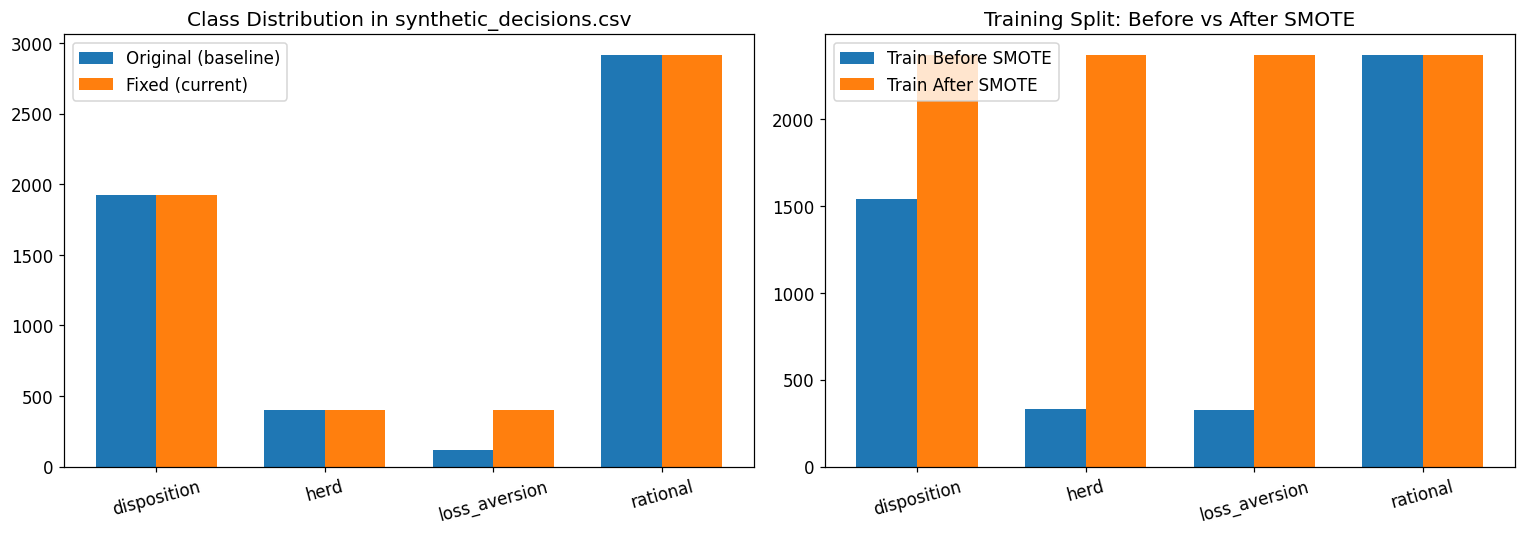

loss_aversion count before fix (baseline): 114
loss_aversion count after fix: 400


In [17]:
decisions = pd.read_csv(DECISIONS_PATH)
after_counts = decisions['bias_type'].value_counts()

# Historical baseline from prior evaluation run (documented issue state).
before_loss_aversion_total = 114
before_counts = after_counts.copy()
before_counts['loss_aversion'] = before_loss_aversion_total

train_before_smote = pd.Series(y_train).value_counts().sort_index()
X_train_smote_vis, y_train_smote_vis = SMOTE(random_state=42, k_neighbors=3).fit_resample(X_train, y_train)
train_after_smote = pd.Series(y_train_smote_vis).value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

labels = ['disposition', 'herd', 'loss_aversion', 'rational']
before_vals = [before_counts.get(k, 0) for k in labels]
after_vals = [after_counts.get(k, 0) for k in labels]

x = np.arange(len(labels))
w = 0.36
axes[0].bar(x - w/2, before_vals, width=w, label='Original (baseline)')
axes[0].bar(x + w/2, after_vals, width=w, label='Fixed (current)')
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, rotation=15)
axes[0].set_title('Class Distribution in synthetic_decisions.csv')
axes[0].legend()

idx_labels = [BIAS_LABELS[i] for i in sorted(train_before_smote.index)]
axes[1].bar(np.arange(len(idx_labels)) - w/2, train_before_smote.values, width=w, label='Train Before SMOTE')
axes[1].bar(np.arange(len(idx_labels)) + w/2, [train_after_smote.get(i, 0) for i in sorted(train_before_smote.index)], width=w, label='Train After SMOTE')
axes[1].set_xticks(np.arange(len(idx_labels)))
axes[1].set_xticklabels(idx_labels, rotation=15)
axes[1].set_title('Training Split: Before vs After SMOTE')
axes[1].legend()

plt.tight_layout()
plt.show()

print('loss_aversion count before fix (baseline):', before_loss_aversion_total)
print('loss_aversion count after fix:', int(after_counts.get('loss_aversion', 0)))

## Section 2 - Hyperparameter Search

Fitting 5 folds for each of 40 candidates, totalling 200 fits


Best params: {'subsample': 0.7, 'reg_lambda': 2.0, 'reg_alpha': 0.1, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 5, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
Best CV Macro F1: 0.8584


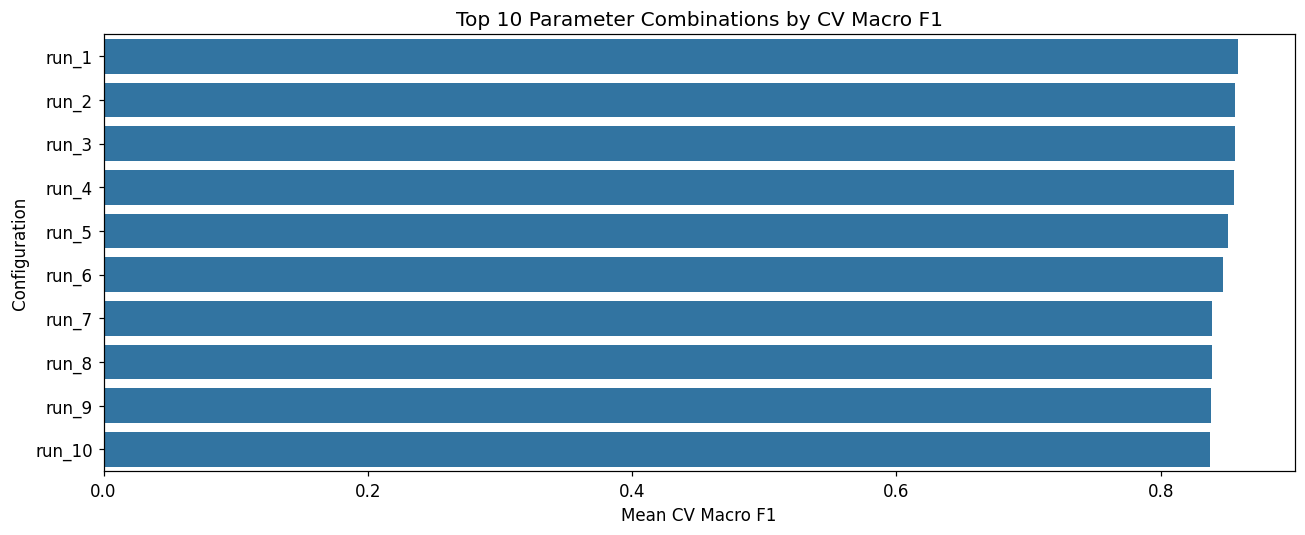

In [18]:
param_grid = {
    'max_depth': [3, 4, 5],
    'n_estimators': [300, 500, 700],
    'learning_rate': [0.01, 0.02, 0.05],
    'subsample': [0.6, 0.7, 0.8],
    'colsample_bytree': [0.6, 0.7, 0.8],
    'min_child_weight': [3, 5, 7, 10],
    'reg_alpha': [0, 0.1, 0.5, 1.0],
    'reg_lambda': [1.0, 1.5, 2.0],
}

search = RandomizedSearchCV(
    estimator=xgb.XGBClassifier(
        objective='multi:softprob',
        num_class=4,
        use_label_encoder=False,
        random_state=42,
        n_jobs=-1,
        eval_metric='mlogloss',
    ),
    param_distributions=param_grid,
    n_iter=40,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
    random_state=42,
    verbose=1,
)

search.fit(X_train, y_train)
print('Best params:', search.best_params_)
print(f'Best CV Macro F1: {search.best_score_:.4f}')

cv_df = pd.DataFrame(search.cv_results_).sort_values('mean_test_score', ascending=False).head(10)
plt.figure(figsize=(12, 5))
sns.barplot(data=cv_df, x='mean_test_score', y=[f'run_{i+1}' for i in range(len(cv_df))], orient='h')
plt.title('Top 10 Parameter Combinations by CV Macro F1')
plt.xlabel('Mean CV Macro F1')
plt.ylabel('Configuration')
plt.tight_layout()
plt.show()

## Section 3 - Retrain with Best Parameters

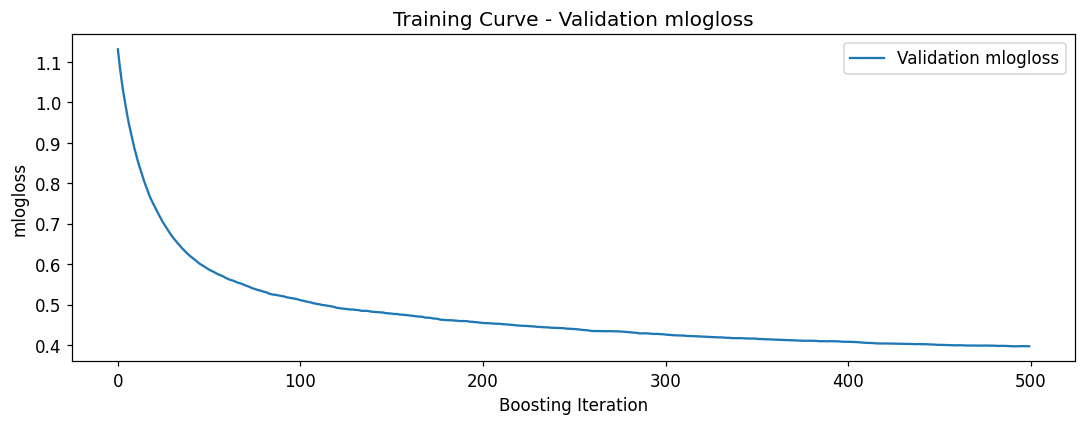

Saved retrained model -> C:\Users\Lenovo\Desktop\Major Project\models\bias_detector_xgboost_v2.pkl
Best iteration: 491


In [19]:
best_params = dict(search.best_params_)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    stratify=y_train,
    random_state=42,
)

sample_weights = compute_sample_weight(
    class_weight={0: 1.0, 1: 1.0, 2: 4.0, 3: 1.0},
    y=y_tr,
)

model_v2 = xgb.XGBClassifier(
    objective='multi:softprob',
    num_class=4,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=30,
    **best_params,
)

model_v2.fit(
    X_tr,
    y_tr,
    sample_weight=sample_weights,
    eval_set=[(X_val, y_val)],
    verbose=False,
)

evals = model_v2.evals_result()

with open(MODEL_V2_EXPERIMENT_PATH, 'wb') as f:
    pickle.dump({'model': model_v2, 'feature_cols': list(X_train.columns)}, f)

plt.figure(figsize=(10, 4))
plt.plot(evals['validation_0']['mlogloss'], label='Validation mlogloss')
plt.title('Training Curve - Validation mlogloss')
plt.xlabel('Boosting Iteration')
plt.ylabel('mlogloss')
plt.legend()
plt.tight_layout()
plt.show()

print('Saved retrained model (experiment) ->', MODEL_V2_EXPERIMENT_PATH)
print('Best iteration:', getattr(model_v2, 'best_iteration', None))

## Section 4 to 9 - Metrics, Learning Curves, Herd Generalisation, Calibration, Summary

Section 4 - Before vs After Metrics


,Metric,Before Fix,After Fix,Change
0,Macro F1 (test),0.7672,0.8668,+0.0996
1,Overfitting Gap,0.1356,0.1242,-0.0114
2,5-Fold CV Macro F1,0.7384,0.8560,+0.1176
3,loss_aversion Recall,0.2414,0.7143,+0.4729
4,loss_aversion F1,0.3590,0.8088,+0.4498
5,herd F1,0.9937,0.9781,-0.0156
6,Train Accuracy,0.9991,0.9757,-0.0234


Section 5 - Updated Classification Report
               precision    recall  f1-score   support

  disposition     0.7905    0.8277    0.8087       383
         herd     1.0000    0.9571    0.9781        70
loss_aversion     0.9322    0.7143    0.8088        77
     rational     0.8691    0.8739    0.8715       547

     accuracy                         0.8514      1077
    macro avg     0.8980    0.8432    0.8668      1077
 weighted avg     0.8542    0.8514    0.8516      1077

Section 6 - Updated Learning Curves


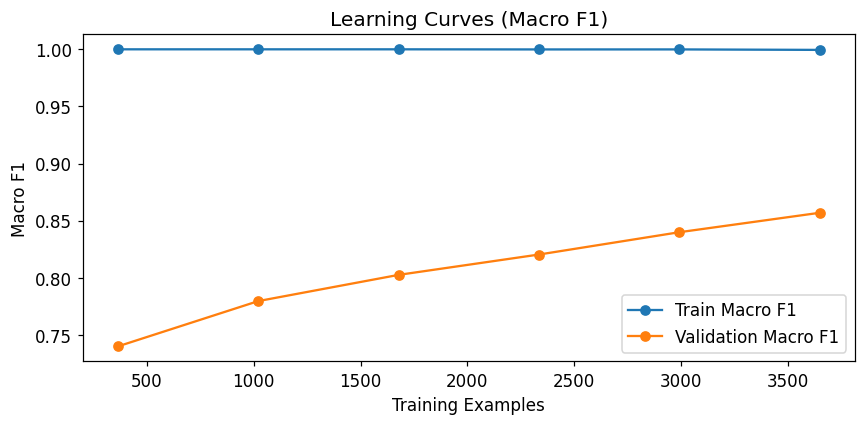

Final train-val learning-curve gap: 0.1426
Section 7 - Herd Generalisation Results
Herd generalisation accuracy: 0.0
Verdict: Model memorised herd generation rule, not generalisable pattern


,sample_id,expected,predicted,predicted_confidence,herd_probability,correct,herd_sensitivity,crowd_action_ratio,market_return_recent,unrealized_gain_loss,risk_tolerance,age
0,0,herd,loss_aversion,0.827573,0.003778,False,0.704791,0.717101,-0.033180,0.067238,2.332372,32
1,1,herd,loss_aversion,0.702804,0.007717,False,0.637776,0.667774,-0.020031,0.068034,3.047849,53
2,2,herd,loss_aversion,0.959274,0.000899,False,0.721720,0.691309,-0.133111,-0.044342,2.320292,31
3,3,herd,loss_aversion,0.991294,0.001211,False,0.689474,0.741250,-0.066839,-0.105221,5.546863,52
4,4,herd,loss_aversion,0.606062,0.002933,False,0.568835,0.708680,-0.141677,0.031604,6.084287,39
5,5,herd,loss_aversion,0.582326,0.006245,False,0.745124,0.688395,-0.051202,-0.001502,4.361783,30
6,6,herd,loss_aversion,0.986632,0.000511,False,0.702228,0.689802,-0.084028,-0.087903,3.907947,34
7,7,herd,loss_aversion,0.994928,0.000151,False,0.707213,0.625988,-0.121095,-0.171660,5.027157,42
8,8,herd,loss_aversion,0.800029,0.001743,False,0.575623,0.557704,-0.129319,0.024037,7.250030,51
9,9,herd,loss_aversion,0.988832,0.000561,False,0.640077,0.659179,-0.032471,-0.121262,7.106790,45


Section 8 - Updated Calibration Curves (v1 vs v2)


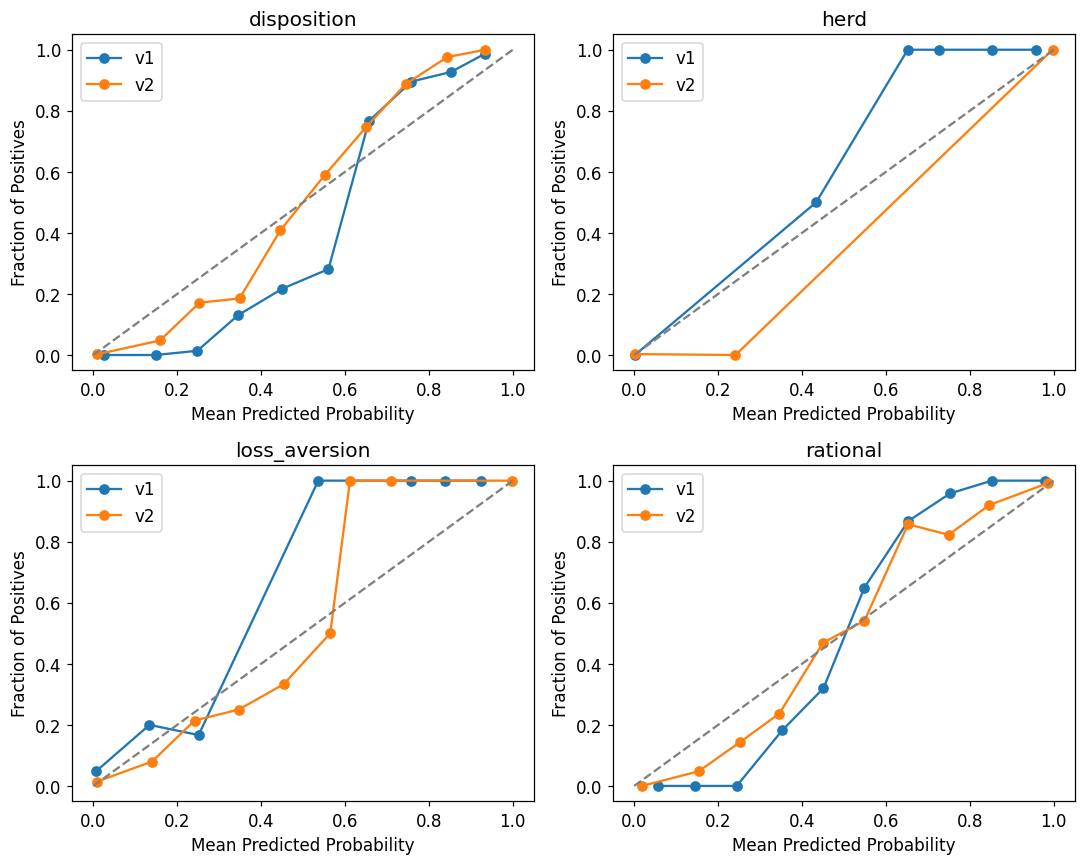

Section 9 - Updated Summary Card

+------------------------------------------------------------+
|            MODEL IMPROVEMENT SUMMARY - v1 vs v2           |
+---------------------------+---------------+----------------+
| Metric                    | v1 (before)   | v2 (after)     |
+---------------------------+---------------+----------------+
| Macro F1 (test)           |  76.72%      |  86.68%       |
| Overfitting Gap           |  13.56%      |  12.42%       |
| 5-Fold CV Macro F1        |  73.84%      |  85.60%       |
| loss_aversion Recall      |  24.14%      |  71.43%       |
| loss_aversion F1          |  35.90%      |  80.88%       |
+---------------------------+---------------+----------------+

Saved updated evaluation report -> C:\Users\Lenovo\Desktop\Major Project\results\model_evaluation_report_v2.json


In [20]:
# Evaluate current v2 model.
y_pred_train = model_v2.predict(X_train)
y_pred_test = model_v2.predict(X_test)
y_proba_test = model_v2.predict_proba(X_test)

train_acc = accuracy_score(y_train, y_pred_train)
test_acc = accuracy_score(y_test, y_pred_test)
train_macro_f1 = f1_score(y_train, y_pred_train, average='macro')
test_macro_f1 = f1_score(y_test, y_pred_test, average='macro')

cv_scores = cross_val_score(
    xgb.XGBClassifier(
        objective='multi:softprob',
        num_class=4,
        eval_metric='mlogloss',
        random_state=42,
        n_jobs=-1,
        **best_params,
    ),
    X_train,
    y_train,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='f1_macro',
    n_jobs=-1,
)
cv_macro_f1_mean = float(np.mean(cv_scores))
cv_macro_f1_std = float(np.std(cv_scores))

report_dict = classification_report(y_test, y_pred_test, target_names=[BIAS_LABELS[i] for i in range(4)], output_dict=True)

before = {
    'Macro F1 (test)': 0.7672,
    'Overfitting Gap': 0.1356,
    '5-Fold CV Macro F1': 0.7384,
    'loss_aversion Recall': 0.2414,
    'loss_aversion F1': 0.3590,
    'herd F1': 0.9937,
    'Train Accuracy': 0.9991,
}
after = {
    'Macro F1 (test)': test_macro_f1,
    'Overfitting Gap': train_acc - test_acc,
    '5-Fold CV Macro F1': cv_macro_f1_mean,
    'loss_aversion Recall': report_dict['loss_aversion']['recall'],
    'loss_aversion F1': report_dict['loss_aversion']['f1-score'],
    'herd F1': report_dict['herd']['f1-score'],
    'Train Accuracy': train_acc,
}

cmp = pd.DataFrame({
    'Metric': list(before.keys()),
    'Before Fix': [before[k] for k in before],
    'After Fix': [after[k] for k in before],
})
cmp['Change'] = cmp['After Fix'] - cmp['Before Fix']

print('Section 4 - Before vs After Metrics')
display(cmp.style.format({'Before Fix': '{:.4f}', 'After Fix': '{:.4f}', 'Change': '{:+.4f}'}))

print('Section 5 - Updated Classification Report')
print(classification_report(y_test, y_pred_test, target_names=[BIAS_LABELS[i] for i in range(4)], digits=4))
for cls in ['disposition', 'herd', 'loss_aversion', 'rational']:
    rec = report_dict[cls]['recall']
    f1v = report_dict[cls]['f1-score']
    if rec < 0.60:
        print(f'WARNING: {cls} recall {rec:.4f} < 0.60')
    if f1v < 0.50:
        print(f'CRITICAL: {cls} f1 {f1v:.4f} < 0.50')

print('Section 6 - Updated Learning Curves')
cv_est = xgb.XGBClassifier(
    objective='multi:softprob',
    num_class=4,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1,
    **best_params,
)
sizes, train_scores, val_scores = learning_curve(
    cv_est, X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 6),
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
)
train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

plt.figure(figsize=(8, 4))
plt.plot(sizes, train_mean, marker='o', label='Train Macro F1')
plt.plot(sizes, val_mean, marker='o', label='Validation Macro F1')
plt.title('Learning Curves (Macro F1)')
plt.xlabel('Training Examples')
plt.ylabel('Macro F1')
plt.legend()
plt.tight_layout()
plt.show()
print(f'Final train-val learning-curve gap: {train_mean[-1] - val_mean[-1]:.4f}')

print('Section 7 - Herd Generalisation Results')
if HERD_REPORT_PATH.exists():
    with open(HERD_REPORT_PATH, 'r', encoding='utf-8') as f:
        herd_report = json.load(f)
    print('Herd generalisation accuracy:', herd_report.get('accuracy'))
    print('Verdict:', herd_report.get('verdict'))
    herd_samples = pd.DataFrame(herd_report.get('samples', []))
    display(herd_samples.head(60))
else:
    print('Herd report not found:', HERD_REPORT_PATH)

print('Section 8 - Updated Calibration Curves (v1 vs v2)')
def load_bundle(path):
    with open(path, 'rb') as f:
        return pickle.load(f)

if MODEL_V1_PATH.exists():
    b1 = load_bundle(MODEL_V1_PATH)
    m1 = b1['model']
    f1_cols = b1['feature_cols']
    X_test_v1 = X_test.copy()
    for c in f1_cols:
        if c not in X_test_v1.columns:
            X_test_v1[c] = 0.0
    X_test_v1 = X_test_v1[f1_cols]
    p1 = m1.predict_proba(X_test_v1)

    y_bin = label_binarize(y_test, classes=[0, 1, 2, 3])
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    axes = axes.flatten()
    for i, cls in enumerate([0, 1, 2, 3]):
        fr1, mp1 = calibration_curve(y_bin[:, i], p1[:, i], n_bins=10)
        fr2, mp2 = calibration_curve(y_bin[:, i], y_proba_test[:, i], n_bins=10)
        axes[i].plot(mp1, fr1, marker='o', label='v1')
        axes[i].plot(mp2, fr2, marker='o', label='v2')
        axes[i].plot([0, 1], [0, 1], '--', color='gray')
        axes[i].set_title(BIAS_LABELS[cls])
        axes[i].set_xlabel('Mean Predicted Probability')
        axes[i].set_ylabel('Fraction of Positives')
        axes[i].legend()
    plt.tight_layout()
    plt.show()
else:
    print('Original v1 model not found, skipping direct calibration comparison plot.')

summary_card = f'''
+------------------------------------------------------------+
|            MODEL IMPROVEMENT SUMMARY - v1 vs v2           |
+---------------------------+---------------+----------------+
| Metric                    | v1 (before)   | v2 (after)     |
+---------------------------+---------------+----------------+
| Macro F1 (test)           | {before['Macro F1 (test)']*100:6.2f}%      | {after['Macro F1 (test)']*100:6.2f}%       |
| Overfitting Gap           | {before['Overfitting Gap']*100:6.2f}%      | {after['Overfitting Gap']*100:6.2f}%       |
| 5-Fold CV Macro F1        | {before['5-Fold CV Macro F1']*100:6.2f}%      | {after['5-Fold CV Macro F1']*100:6.2f}%       |
| loss_aversion Recall      | {before['loss_aversion Recall']*100:6.2f}%      | {after['loss_aversion Recall']*100:6.2f}%       |
| loss_aversion F1          | {before['loss_aversion F1']*100:6.2f}%      | {after['loss_aversion F1']*100:6.2f}%       |
+---------------------------+---------------+----------------+
'''
print('Section 9 - Updated Summary Card')
print(summary_card)

report_v2 = {
    'train_accuracy': train_acc,
    'test_accuracy': test_acc,
    'overfitting_gap': train_acc - test_acc,
    'macro_f1': test_macro_f1,
    'train_macro_f1': train_macro_f1,
    'test_macro_f1': test_macro_f1,
    'overfitting_gap_f1': train_macro_f1 - test_macro_f1,
    'best_iteration': int(getattr(model_v2, 'best_iteration', -1)),
    'cv_macro_f1_mean': cv_macro_f1_mean,
    'cv_macro_f1_std': cv_macro_f1_std,
    'classification_report': report_dict,
}
with open(REPORT_V2_EXPERIMENT_PATH, 'w', encoding='utf-8') as f:
    json.dump(report_v2, f, indent=2)
print('Saved updated evaluation report (experiment) ->', REPORT_V2_EXPERIMENT_PATH)